In [1]:

import pandas as pd
df=pd.read_csv(r"C:\Users\Lenovo\Downloads\archive (4)\spam.csv",encoding='latin-1')

In [2]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
df=df.drop(['Unnamed: 2','Unnamed: 3','Unnamed: 4'],axis=1)
df=df.rename(columns={'v1':'lable','v2':'text'})
df.head()

,lable,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df['lable'].value_counts()

lable
ham     4825
spam     747
Name: count, dtype: int64

In [5]:
import re
def clean_text(text):
    text=text.lower()
    text=re.sub(r'[^\w\s]','',text)
    return text
df['text']=df['text'].apply(clean_text)

In [6]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words=set(stopwords.words('english'))
def remove_stopwords(text):
    words=text.split()
    filtered=[word for word in words if word not in stop_words]
    return" ".join(filtered)
df['text']=df['text'].apply(remove_stopwords)
    
    

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
df['text'].head()

0    go jurong point crazy available bugis n great ...
1                              ok lar joking wif u oni
2    free entry 2 wkly comp win fa cup final tkts 2...
3                  u dun say early hor u c already say
4          nah dont think goes usf lives around though
Name: text, dtype: object

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
x=tfidf.fit_transform(df['text'])
y=df['lable']

In [9]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [10]:
from sklearn.linear_model import LogisticRegression

In [11]:
model=LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Accuracy 0.9417040358744395
[[961   4]
 [ 61  89]]
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       965
        spam       0.96      0.59      0.73       150

    accuracy                           0.94      1115
   macro avg       0.95      0.79      0.85      1115
weighted avg       0.94      0.94      0.94      1115



In [13]:
model=LogisticRegression(class_weight='balanced',max_iter=1000)

In [14]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Accuracy 0.9417040358744395
[[961   4]
 [ 61  89]]
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       965
        spam       0.96      0.59      0.73       150

    accuracy                           0.94      1115
   macro avg       0.95      0.79      0.85      1115
weighted avg       0.94      0.94      0.94      1115



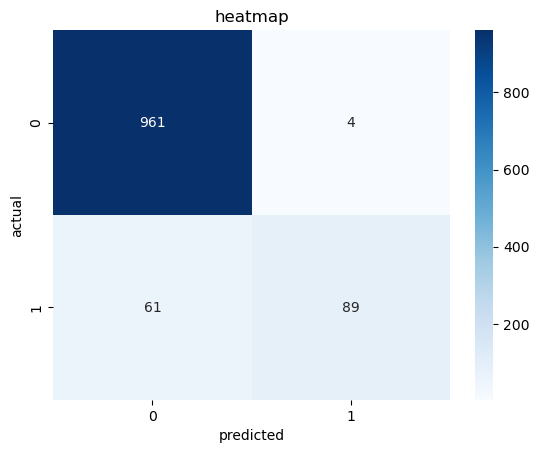

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("predicted")
plt.ylabel('actual')
plt.title("heatmap")
plt.show()

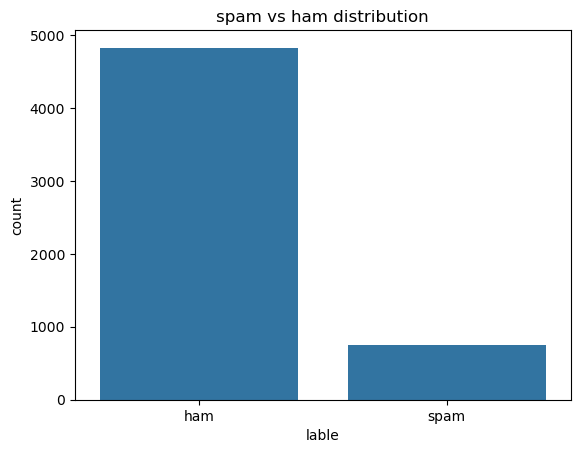

In [16]:
sns.countplot(x=df['lable'])
plt.title("spam vs ham distribution")
plt.show()

In [17]:
# ====== IMPORTS ======
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# ====== VECTORIZATION ======
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['text'])
y = df['lable']

# ====== SPLIT ======
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# ====== MODEL ======
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model trained successfully ✅")

# ====== USER INPUT ======
user_input = input("Enter a message: ")

# preprocessing
cleaned = clean_text(user_input)
cleaned = remove_stopwords(cleaned)

# vectorize
vector = tfidf.transform([cleaned])

# prediction
prediction = model.predict(vector)[0]
probability = model.predict_proba(vector)[0]

# output
if prediction == 'spam':
    print("⚠️ This is SPAM")
else:
    print("✅ This is HAM")

print(f"Spam Probability: {probability[1]:.2f}")


import re

def predict_spam(message):
    message_tfidf = tfidf.transform([message])

    # Get hybrid model prediction
    probabilities = hybrid_model.predict_proba(message_tfidf)[0]
    spam_index = list(hybrid_model.classes_).index(1)
    spam_probability = probabilities[spam_index]

    text = message.lower().strip()

    # Detect strong spam patterns
    strong_spam_patterns = [
        r'\bfree\s+free\b',
        r'\bwon\b.*\b(prize|cash|reward|voucher)\b',
        r'\b(claim|collect)\b.*\b(prize|reward|cash|offer)\b',
        r'\b(congratulations|winner|winning)\b',
        r'\b(click here|call now)\b',
        r'\b\d+%\s*off\b',
        r'\b(urgent|limited time offer)\b'
    ]

    suspicious_pattern = any(
        re.search(pattern, text) for pattern in strong_spam_patterns
    )

    # Override only when a strong spam pattern is detected
    if suspicious_pattern:
        prediction = 1
        confidence = max(spam_probability, 0.90)
    else:
        prediction = int(spam_probability >= 0.50)
        confidence = (
            spam_probability if prediction == 1
            else 1 - spam_probability
        )

    result = "SPAM MESSAGE" if prediction == 1 else "HAM (LEGITIMATE MESSAGE)"

    print("\nMessage:", message)
    print("Prediction:", result)
    print("Model confidence: {:.2f}%".format(confidence * 100))

    return result


### Test it immediately



import re

def predict_spam(message):
    message_tfidf = tfidf.transform([message])

    # Get hybrid model prediction
    probabilities = hybrid_model.predict_proba(message_tfidf)[0]
    spam_index = list(hybrid_model.classes_).index(1)
    spam_probability = probabilities[spam_index]

    text = message.lower().strip()

    # Detect strong spam patterns
    strong_spam_patterns = [
        r'\bfree\s+free\b',
        r'\bwon\b.*\b(prize|cash|reward|voucher)\b',
        r'\b(claim|collect)\b.*\b(prize|reward|cash|offer)\b',
        r'\b(congratulations|winner|winning)\b',
        r'\b(click here|call now)\b',
        r'\b\d+%\s*off\b',
        r'\b(urgent|limited time offer)\b'
    ]

    suspicious_pattern = any(
        re.search(pattern, text) for pattern in strong_spam_patterns
    )

    # Override only when a strong spam pattern is detected
    if suspicious_pattern:
        prediction = 1
        confidence = max(spam_probability, 0.90)
    else:
        prediction = int(spam_probability >= 0.50)
        confidence = (
            spam_probability if prediction == 1
            else 1 - spam_probability
        )

    result = "SPAM MESSAGE" if prediction == 1 else "HAM (LEGITIMATE MESSAGE)"

    print("\nMessage:", message)
    print("Prediction:", result)
    print("Model confidence: {:.2f}%".format(confidence * 100))

    return result








Model trained successfully ✅


Enter a message:  free free free


⚠️ This is SPAM
Spam Probability: 0.74


       HYBRID SMS SPAM DETECTION SYSTEM

Dataset loaded successfully!
Dataset shape: (5572, 5)

Available columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Preprocessing completed.
Total messages: 5169
Ham messages: 4516
Spam messages: 653

Training samples: 4135
Testing samples: 1034

TF-IDF feature extraction completed.
Number of features: 10000

TRAINING INDIVIDUAL MODELS

Training Logistic Regression...
Logistic Regression Accuracy: 97.68%

Training Random Forest...
Random Forest Accuracy: 97.68%

Training XGBoost...
XGBoost Accuracy: 96.62%

Training Hybrid Ensemble Model...

Hybrid Ensemble Accuracy: 98.16%

MODEL ACCURACY COMPARISON
Logistic Regression      : 97.68%
Random Forest            : 97.68%
XGBoost                  : 96.62%
Hybrid Ensemble          : 98.16%

Best-performing model: Hybrid Ensemble
Best accuracy: 98.16%

HYBRID ENSEMBLE CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Ham (Legitimate)       0.98      1.00    

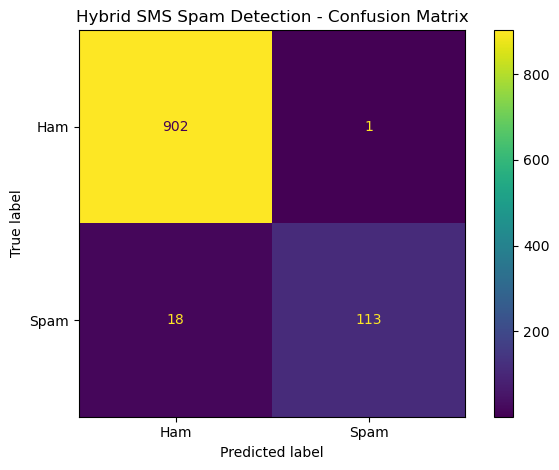

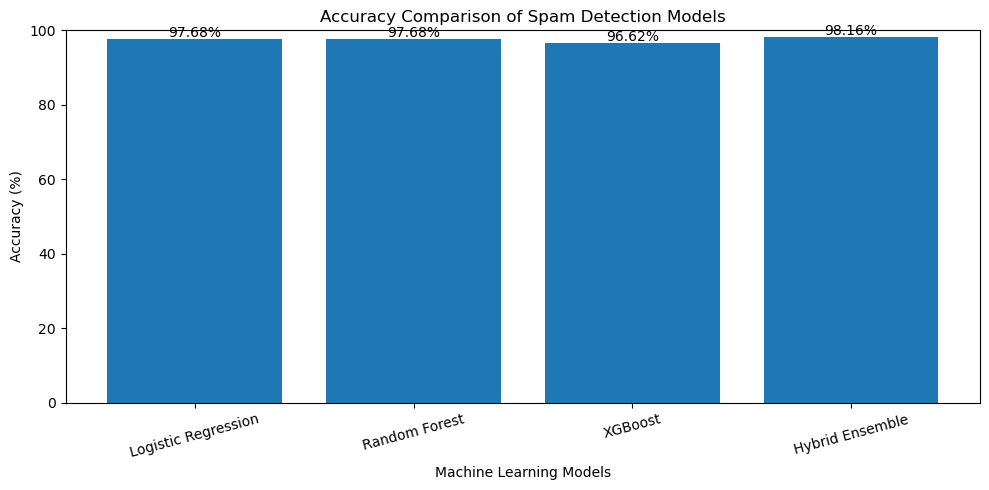

In [18]:

# ============================================================
# HYBRID SMS SPAM DETECTION PROJECT
# Logistic Regression + Random Forest + XGBoost
# Name: Moksh Mishra
# Dataset: C:\Users\Lenovo\Downloads\spaammmm.csv
# ============================================================

import sys
import subprocess
import importlib.util
import warnings

warnings.filterwarnings("ignore")

# -------------------- 1. INSTALL XGBOOST --------------------

if importlib.util.find_spec("xgboost") is None:
    print("Installing XGBoost...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "xgboost"]
    )

# -------------------- 2. IMPORT LIBRARIES --------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

print("=" * 60)
print("       HYBRID SMS SPAM DETECTION SYSTEM")
print("=" * 60)

# -------------------- 3. LOAD DATASET --------------------

file_path = r"C:\Users\Lenovo\Downloads\spaammmm.csv"

df = pd.read_csv(file_path, encoding="latin-1")

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nAvailable columns:", df.columns.tolist())

# -------------------- 4. PREPROCESS DATA --------------------

# Support the standard SMS Spam Collection dataset
if "v1" in df.columns and "v2" in df.columns:
    df = df[["v1", "v2"]].copy()
    df.columns = ["label", "text"]

# Also support datasets with label/text column names
elif "label" in df.columns and "text" in df.columns:
    df = df[["label", "text"]].copy()

else:
    raise ValueError(
        "Dataset columns were not recognized. "
        "Expected v1/v2 or label/text columns."
    )

df.dropna(subset=["label", "text"], inplace=True)

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["text"] = df["text"].astype(str)

# Convert ham/spam labels into numerical labels
df = df[df["label"].isin(["ham", "spam"])].copy()
df["label"] = df["label"].map({"ham": 0, "spam": 1})

df.drop_duplicates(subset=["text"], inplace=True)
df.reset_index(drop=True, inplace=True)

print("\nPreprocessing completed.")
print("Total messages:", len(df))
print("Ham messages:", (df["label"] == 0).sum())
print("Spam messages:", (df["label"] == 1).sum())

# -------------------- 5. SPLIT DATA --------------------

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# -------------------- 6. TF-IDF FEATURE EXTRACTION --------------------

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF feature extraction completed.")
print("Number of features:", X_train_tfidf.shape[1])

# -------------------- 7. DEFINE MODELS --------------------

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# -------------------- 8. TRAIN INDIVIDUAL MODELS --------------------

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

results = {}
trained_models = {}

print("\n" + "=" * 60)
print("TRAINING INDIVIDUAL MODELS")
print("=" * 60)

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)
    accuracy = accuracy_score(y_test, predictions)

    trained_models[name] = model
    results[name] = accuracy

    print(f"{name} Accuracy: {accuracy * 100:.2f}%")

# -------------------- 9. HYBRID ENSEMBLE --------------------

# Soft voting combines the predicted class probabilities.
# Weights: Logistic Regression = 4, Random Forest = 3,
# XGBoost = 3.

hybrid_model = VotingClassifier(
    estimators=[
        ("lr", logistic_model),
        ("rf", random_forest_model),
        ("xgb", xgb_model)
    ],
    voting="soft",
    weights=[4, 3, 3],
    n_jobs=1
)

print("\nTraining Hybrid Ensemble Model...")
hybrid_model.fit(X_train_tfidf, y_train)

hybrid_predictions = hybrid_model.predict(X_test_tfidf)
hybrid_accuracy = accuracy_score(y_test, hybrid_predictions)

results["Hybrid Ensemble"] = hybrid_accuracy

print("\nHybrid Ensemble Accuracy: {:.2f}%".format(
    hybrid_accuracy * 100
))

# -------------------- 10. MODEL COMPARISON --------------------

print("\n" + "=" * 60)
print("MODEL ACCURACY COMPARISON")
print("=" * 60)

for name, accuracy in results.items():
    print(f"{name:<25}: {accuracy * 100:.2f}%")

best_model_name = max(results, key=results.get)

print("\nBest-performing model:", best_model_name)
print("Best accuracy: {:.2f}%".format(
    results[best_model_name] * 100
))

# -------------------- 11. CLASSIFICATION REPORT --------------------

print("\n" + "=" * 60)
print("HYBRID ENSEMBLE CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    hybrid_predictions,
    labels=[0, 1],
    target_names=["Ham (Legitimate)", "Spam"],
    zero_division=0
))

# -------------------- 12. CONFUSION MATRIX --------------------

cm = confusion_matrix(
    y_test,
    hybrid_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot(values_format="d")
plt.title("Hybrid SMS Spam Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

# -------------------- 13. ACCURACY COMPARISON GRAPH --------------------

plt.figure(figsize=(10, 5))

model_names = list(results.keys())
accuracies = [results[name] * 100 for name in model_names]

bars = plt.bar(model_names, accuracies)

plt.title("Accuracy Comparison of Spam Detection Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()




